# 04 — Avaliação com juiz LLM e validação humana

Este notebook avalia as 111 respostas geradas pelo LexIA (Qwen3 8B, notebook 03) com o protocolo **LLM-as-a-Judge** e confere o juiz contra duas avaliações humanas: a revisora (9 respostas históricas) e um advogado (25 respostas, às cegas).

## Juiz

O juiz é o **`gemma3:27b`** (Google), no Ollama, na GPU T4 do Kaggle. Ele é de família diferente do gerador e foi adotado em 2026-11-17, depois que o Gemma 3 12B foi descartado na calibração. Para cada resposta, ele devolve um JSON com:

| Critério | Escala | O que avalia |
|---|---|---|
| **Fidelidade** | 0 a 2 | As afirmações estão apoiadas nas fontes entregues? |
| **Correção** | 0 a 2 | A resposta cobre os pontos jurídicos da resposta de referência da curadoria? |
| **Comportamento** | 0 a 2 | Informa sem prestar consultoria individual? |
| **Clareza** | 0 a 2 | Linguagem simples para o trabalhador leigo? |
| **Afirmações** | lista | Cada afirmação, classificada como `apoiada`, `sem_apoio` ou `contradita`. |
| **Pertinência da jurisprudência** | sim/não | Cada decisão entregue era pertinente à pergunta? |
| **Veredito** | aprovada/reprovada | Veredito do próprio modelo, com justificativa. |

## Veredito pela regra fixa

O veredito do próprio modelo não acompanha as notas que ele mesmo dá. Por isso o resultado oficial é a **regra fixa** (`juiz.veredito_regra`), declarada antes de ver os resultados do 27B. A resposta é reprovada se:
- o juiz a reprovou;
- fidelidade, correção ou comportamento ficou abaixo de 2;
- alguma afirmação ficou sem apoio ou foi contradita pelas fontes.

## Conjuntos

1. **Calibração (9):** respostas históricas avaliadas por uma revisora especializada em Direito do Trabalho.
2. **Geração (111):** respostas do `qwen3:8b-q8_0` no fluxo integrado de legislação e jurisprudência.
3. **Validação com especialista (25 das 111):** amostra sorteada (15 aprovadas e 10 reprovadas pela regra), avaliada por um advogado às cegas, sem ver nada do juiz.

## 1. Configuração e carga dos dados

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/integracao').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RELATORIOS = ROOT / 'reports/integracao/juiz'
BASE_KAGGLE = ROOT / 'output/kaggle/juiz_27b'
APROVADA, REPROVADA, NEUTRA = '#2ca02c', '#d62728', '#7f7f7f'

df_calib = pd.read_csv(RELATORIOS / 'calibracao_27b.csv')
df_julg = pd.read_csv(RELATORIOS / 'julgamentos_27b.csv')
df_julg['id'] = df_julg.julgamento_id.str.removeprefix('ger_')
df_humano = pd.read_csv(RELATORIOS / 'concordancia_humano_27b.csv')
df_diag = pd.read_csv(RELATORIOS / 'diagnostico_especialista_27b.csv')
df_fontes = pd.read_csv(RELATORIOS / 'marcacao_fontes_geracao.csv')

julgamentos_completos = []
arquivo_julg = BASE_KAGGLE / 'julgamentos.jsonl'   # fora do Git; só para os exemplos da seção 6
if arquivo_julg.exists():
    julgamentos_completos = [json.loads(l) for l in arquivo_julg.read_text(encoding='utf-8').splitlines() if l.strip()]

print(f'Calibração: {len(df_calib)} · geração: {len(df_julg)} (válidos: {df_julg.valido.sum()}) · '
      f'especialista: {len(df_humano)} · julgamentos completos locais: {len(julgamentos_completos)}')

Calibração: 9 · geração: 111 (válidos: 111) · especialista: 25 · julgamentos completos locais: 120


## 2. Calibração com a revisora (9 respostas históricas)

O juiz avaliou às cegas as 9 respostas históricas que a revisora já tinha julgado. A comparação mostra os dois vereditos do juiz: o do próprio modelo e o da regra fixa.

In [2]:
total = len(df_calib)
print(f"Veredito do modelo: concorda com a revisora em {df_calib.concorda.sum()} de {total}")
print(f"Regra fixa:         concorda com a revisora em {df_calib.concorda_regra.sum()} de {total}")
reprov = df_calib[df_calib.humano == 'reprovada']
print(f"Reprovadas pela revisora: {len(reprov)} · detectadas pelo modelo: {(reprov.veredito == 'reprovada').sum()}"
      f" · pela regra: {(reprov.veredito_regra == 'reprovada').sum()}")

colunas = ['julgamento_id', 'humano', 'veredito', 'veredito_regra', 'fidelidade', 'correcao', 'comportamento', 'clareza', 'sem_apoio']
display(df_calib[colunas].rename(columns={'humano': 'revisora', 'veredito': 'veredito_modelo'}))

Veredito do modelo: concorda com a revisora em 7 de 9
Regra fixa:         concorda com a revisora em 8 de 9
Reprovadas pela revisora: 3 · detectadas pelo modelo: 1 · pela regra: 3


,julgamento_id,revisora,veredito_modelo,veredito_regra,fidelidade,correcao,comportamento,clareza,sem_apoio
0,calib_q_test_01,aprovada,aprovada,aprovada,2,2.0,2,2,0
1,calib_q_test_02,aprovada,aprovada,reprovada,2,2.0,1,2,0
2,calib_q_test_03,reprovada,aprovada,reprovada,2,2.0,1,2,0
3,calib_q_test_04,aprovada,aprovada,aprovada,2,2.0,2,2,0
4,calib_q_test_05,reprovada,aprovada,reprovada,1,NaN,1,1,2
5,calib_q_test_06,aprovada,aprovada,aprovada,2,2.0,2,2,0
6,calib_q_test_07,aprovada,aprovada,aprovada,2,2.0,2,2,0
7,calib_q_test_08,aprovada,aprovada,aprovada,2,2.0,2,2,0
8,calib_q_test_neg_02,reprovada,reprovada,reprovada,0,NaN,1,2,6


## 3. Desempenho geral das 111 respostas (Qwen3 8B)

Resultado consolidado do juiz nas respostas do fluxo integrado. O veredito oficial é o da regra fixa. O veredito do modelo aparece só para comparação.

,Regra fixa,Veredito do modelo,Regra fixa (%)
aprovada,67,107,60.4
reprovada,44,4,39.6


,Média (0 a 2),Desvio padrão,Respostas com nota
fidelidade,1.80,0.40,111
correcao,1.71,0.53,28
comportamento,1.77,0.50,111
clareza,1.93,0.26,111


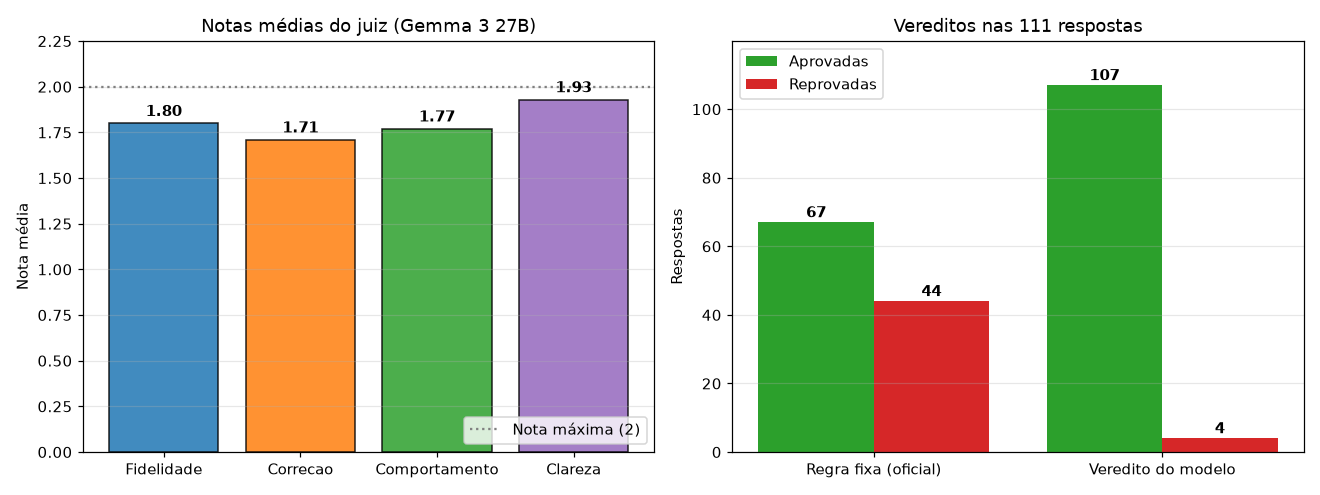

In [3]:
validos = df_julg[df_julg.valido]
contagem = pd.DataFrame({
    'Regra fixa': validos.veredito_regra.value_counts(),
    'Veredito do modelo': validos.veredito.value_counts(),
}).reindex(['aprovada', 'reprovada']).fillna(0).astype(int)
contagem['Regra fixa (%)'] = (contagem['Regra fixa'] / len(validos) * 100).round(1)
display(contagem)

dimensoes = ['fidelidade', 'correcao', 'comportamento', 'clareza']
resumo = pd.DataFrame({'Média (0 a 2)': validos[dimensoes].mean().round(2),
                       'Desvio padrão': validos[dimensoes].std().round(2),
                       'Respostas com nota': validos[dimensoes].notna().sum()})
display(resumo)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
medias = resumo['Média (0 a 2)']
barras = axes[0].bar([d.capitalize() for d in medias.index], medias.values,
                     color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd'], edgecolor='black', alpha=0.85)
axes[0].set_ylim(0, 2.25)
axes[0].axhline(2.0, color='gray', linestyle=':', label='Nota máxima (2)')
axes[0].set_title('Notas médias do juiz (Gemma 3 27B)')
axes[0].set_ylabel('Nota média')
for b in barras:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.04, f'{b.get_height():.2f}', ha='center', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend(loc='lower right')

x = np.arange(2)
axes[1].bar(x - 0.2, contagem.loc['aprovada', ['Regra fixa', 'Veredito do modelo']], 0.4, color=APROVADA, label='Aprovadas')
axes[1].bar(x + 0.2, contagem.loc['reprovada', ['Regra fixa', 'Veredito do modelo']], 0.4, color=REPROVADA, label='Reprovadas')
for i, col in enumerate(['Regra fixa', 'Veredito do modelo']):
    for dx, v in ((-0.2, contagem.loc['aprovada', col]), (0.2, contagem.loc['reprovada', col])):
        axes[1].text(i + dx, v + 1.5, str(v), ha='center', fontweight='bold')
axes[1].set_xticks(x, ['Regra fixa (oficial)', 'Veredito do modelo'])
axes[1].set_ylim(0, len(validos) * 1.08)
axes[1].set_title('Vereditos nas 111 respostas')
axes[1].set_ylabel('Respostas')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'desempenho_juiz.png', dpi=150)
plt.show()

## 4. Suporte das afirmações nas fontes

O juiz dividiu cada resposta em afirmações e conferiu se cada uma tinha apoio nas fontes entregues.

Afirmações analisadas: 817
Com apoio nas fontes: 758 (92.8%)
Sem apoio ou contraditas: 59 (7.2%)
Respostas com pelo menos uma afirmação sem apoio: 35 de 111


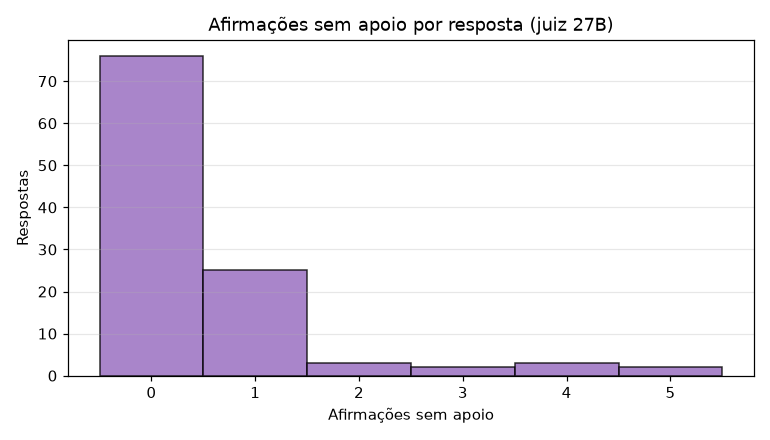

In [4]:
total_afirmacoes = int(validos['afirmacoes'].sum())
total_sem_apoio = int(validos['sem_apoio'].sum())
print(f'Afirmações analisadas: {total_afirmacoes}')
print(f'Com apoio nas fontes: {total_afirmacoes - total_sem_apoio} ({(1 - total_sem_apoio / total_afirmacoes):.1%})')
print(f'Sem apoio ou contraditas: {total_sem_apoio} ({total_sem_apoio / total_afirmacoes:.1%})')
print(f'Respostas com pelo menos uma afirmação sem apoio: {(validos.sem_apoio > 0).sum()} de {len(validos)}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(validos['sem_apoio'], bins=range(0, int(validos['sem_apoio'].max()) + 2), color='#9467bd',
        edgecolor='black', alpha=0.8, align='left')
ax.set_title('Afirmações sem apoio por resposta (juiz 27B)')
ax.set_xlabel('Afirmações sem apoio')
ax.set_ylabel('Respostas')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'distribuicao_alucinacoes.png', dpi=150)
plt.show()

## 5. Pertinência da jurisprudência entregue

O juiz avaliou cada decisão judicial entregue pela busca híbrida, uma por uma.

Decisões entregues: 243 · julgadas pertinentes: 222 (91.4%)


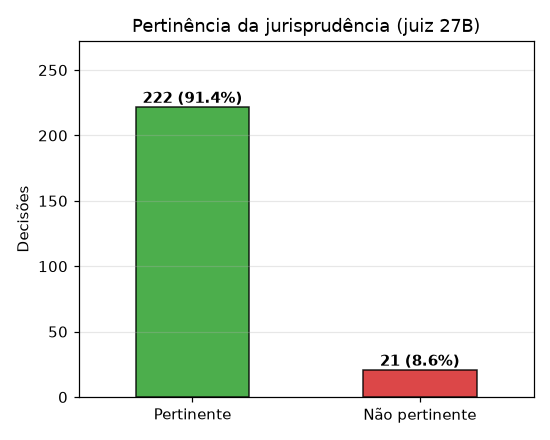

In [5]:
entregue = int(validos['jurisprudencia_entregue'].sum())
pertinente = int(validos['jurisprudencia_pertinente'].sum())
print(f'Decisões entregues: {entregue} · julgadas pertinentes: {pertinente} ({pertinente / entregue:.1%})')

resumo_jus = pd.Series({'Pertinente': pertinente, 'Não pertinente': entregue - pertinente})
fig, ax = plt.subplots(figsize=(5, 4))
resumo_jus.plot(kind='bar', color=[APROVADA, REPROVADA], edgecolor='black', ax=ax, alpha=0.85, rot=0)
ax.set_title('Pertinência da jurisprudência (juiz 27B)')
ax.set_ylabel('Decisões')
for i, v in enumerate(resumo_jus):
    ax.text(i, v + 3, f'{v} ({v / entregue:.1%})', ha='center', fontweight='bold')
ax.set_ylim(0, entregue * 1.12)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'pertinencia_jurisprudencia.png', dpi=150)
plt.show()

## 6. Exemplos de justificativas do juiz

Uma resposta aprovada e uma reprovada pela regra fixa. A justificativa só aparece quando os julgamentos completos estão na máquina, em `output/kaggle/juiz_27b/`, pasta que fica fora do Git.

A resposta aprovada do exemplo, sobre trabalho noturno (q09_p1_JUS-001), está na amostra do advogado, e ele a reprovou: tirou a condição da Súmula 60 e ignorou as regras do doméstico e do rural, que estavam nas fontes (seções 7 e 8).

In [6]:
julg_map = {j['julgamento_id']: j for j in julgamentos_completos}
for rotulo, regra in (('aprovada', 'aprovada'), ('reprovada', 'reprovada')):
    jid = validos[validos.veredito_regra == regra].iloc[0]['julgamento_id']
    j = julg_map.get(jid)
    if not j:
        print(f'{jid}: julgamento completo não disponível nesta máquina.')
        continue
    sem = sum(a.get('suporte') in ('sem_apoio', 'contradita') for a in j.get('afirmacoes') or [])
    display(Markdown(f"### Resposta {rotulo} pela regra (`{jid}`)\n"
                     f"**Veredito do modelo:** `{j.get('veredito')}` · **Regra:** `{j.get('veredito_regra')}` · "
                     f"**Fidelidade:** {j.get('fidelidade')} · **Correção:** {j.get('correcao')} · "
                     f"**Afirmações sem apoio:** {sem}  \n**Justificativa do juiz:**  \n> *{j.get('justificativa')}*"))

### Resposta aprovada pela regra (`ger_q09_p1_JUS-001`)
**Veredito do modelo:** `aprovada` · **Regra:** `aprovada` · **Fidelidade:** 2 · **Correção:** 2 · **Afirmações sem apoio:** 0  
**Justificativa do juiz:**  
> *A resposta está totalmente apoiada nas fontes fornecidas, abordando a definição de trabalho noturno, o adicional noturno e a influência das normas coletivas. A resposta é clara, completa e segue a ação esperada de responder com base nas fontes.*

### Resposta reprovada pela regra (`ger_q09_p1_JUS-002`)
**Veredito do modelo:** `aprovada` · **Regra:** `reprovada` · **Fidelidade:** 1 · **Correção:** None · **Afirmações sem apoio:** 1  
**Justificativa do juiz:**  
> *A resposta está bem fundamentada nas fontes fornecidas, especialmente nas jurisprudências do TRT-10. A resposta segue a ação esperada (responder) e a linguagem é clara e acessível. A única ressalva é que a última afirmação não encontra suporte direto nas fontes.*

## 7. Validação com especialista (25 respostas às cegas)

Um advogado revisor avaliou 25 das 111 respostas numa página local, sem ver nada do juiz. A amostra foi sorteada com semente fixa: 15 respostas aprovadas e 10 reprovadas pela regra. Ele escreveu uma observação detalhada para cada resposta.

**Como os vereditos foram obtidos:**
- 15 respostas têm veredito marcado na página;
- nas outras 10, o veredito foi lido na própria observação (por exemplo, "insatisfatória" ou "incorreta no ponto central"). A coluna `origem` registra isso, e quatro dessas leituras são incertas;
- as métricas saem nos dois recortes.

Importação: `scripts/importar_revisao_juiz.py`. O arquivo exportado pelo revisor fica fora do Git.

Advogado: {'reprovada': 25} · regra: {'aprovada': 15, 'reprovada': 10} · modelo: {'aprovada': 25}


,recorte,juiz,n,concorda,concordância
0,só marcadas,Regra fixa,15,5,33%
1,só marcadas,Veredito do modelo,15,0,0%
2,marcadas + inferidas,Regra fixa,25,10,40%
3,marcadas + inferidas,Veredito do modelo,25,0,0%


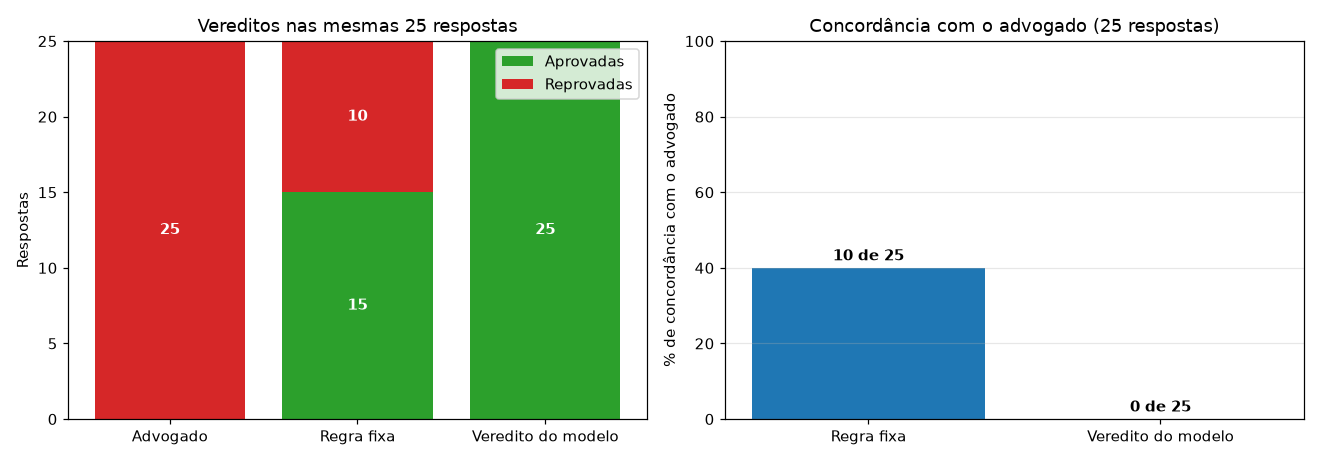

In [7]:
h = df_humano.copy()
print('Advogado:', h.veredito_humano.value_counts().to_dict(),
      '· regra:', h.veredito_regra.value_counts().to_dict(),
      '· modelo:', h.veredito_modelo.value_counts().to_dict())

linhas = []
for nome, recorte in (('só marcadas', h[h.origem == 'marcado']), ('marcadas + inferidas', h)):
    for juiz, coluna in (('Regra fixa', 'veredito_regra'), ('Veredito do modelo', 'veredito_modelo')):
        acerto = int((recorte.veredito_humano == recorte[coluna]).sum())
        linhas.append({'recorte': nome, 'juiz': juiz, 'n': len(recorte), 'concorda': acerto,
                       'concordância': f'{acerto / len(recorte):.0%}'})
tabela = pd.DataFrame(linhas)
display(tabela)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
grupos = ['Advogado', 'Regra fixa', 'Veredito do modelo']
colunas = ['veredito_humano', 'veredito_regra', 'veredito_modelo']
aprov = [int((h[c] == 'aprovada').sum()) for c in colunas]
reprov = [int((h[c] == 'reprovada').sum()) for c in colunas]
axes[0].bar(grupos, aprov, color=APROVADA, label='Aprovadas')
axes[0].bar(grupos, reprov, bottom=aprov, color=REPROVADA, label='Reprovadas')
for i, (a, r) in enumerate(zip(aprov, reprov)):
    if a: axes[0].text(i, a / 2, str(a), ha='center', va='center', color='white', fontweight='bold')
    if r: axes[0].text(i, a + r / 2, str(r), ha='center', va='center', color='white', fontweight='bold')
axes[0].set_title('Vereditos nas mesmas 25 respostas')
axes[0].set_ylabel('Respostas')
axes[0].legend(loc='upper right')

marc = tabela[tabela.recorte == 'marcadas + inferidas']
barras = axes[1].bar(marc.juiz, marc.concorda / marc.n * 100, color=['#1f77b4', NEUTRA])
for b, (_, r) in zip(barras, marc.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{r.concorda} de {r.n}", ha='center', fontweight='bold')
axes[1].set_ylim(0, 100)
axes[1].set_ylabel('% de concordância com o advogado')
axes[1].set_title('Concordância com o advogado (25 respostas)')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'concordancia_especialista.png', dpi=150)
plt.show()

**Leitura.**

1. **O advogado reprovou as 25 respostas.** Ele reprovou até uma que descreveu como "boa resposta" (q_test_08), por imprecisões de prazo e de citação.
2. **O veredito do próprio modelo não serve como critério.** Ele aprovou as 25 e não concordou com o advogado em nenhuma.
3. **A regra fixa vai na direção certa, mas é branda para um especialista.** Ela reprovou 10 e aprovou 15, e o advogado reprovou todas as 15 que ela aprovou.
4. **O que não dá para medir.** Como não houve nenhuma aprovação humana, não se sabe se a regra reprova respostas boas, e o kappa de Cohen fica indefinido.

**Cuidados para interpretar.**

- **Critérios diferentes.** O juiz confere a resposta contra as fontes entregues e a referência da curadoria. O advogado confere contra o direito inteiro: súmulas, redação vigente, completude e utilidade prática. O resultado mede o quanto o juiz é brando diante de um especialista, e não a taxa de acerto dele no próprio critério.
- **Um revisor e 25 respostas.** A amostra serve para apontar padrões, e não para estimar proporções com precisão.
- **Sinais de apoio de IA nas observações.** O texto traz restos de citação de sites e menções a uma "ferramenta", e a observação da FAQ13 trata de outro assunto (consulta ao DataJud). O mais correto é registrar a avaliação como "especialista com apoio de IA".
- **A calibração anterior mostrava outro cenário.** Com a revisora, a regra concordava em 8 de 9, mas eram respostas do sistema anterior, e a revisora também aprovava respostas. Os dois resultados não se contradizem: com um especialista mais exigente, o juiz atual fica brando.

## 8. Diagnóstico do especialista: onde o sistema erra

As 25 observações foram lidas e classificadas por tipo de falha. Uma resposta pode ter vários tipos. A classificação é uma leitura manual das observações, registrada em `DIAGNOSTICO` no `importar_revisao_juiz.py`. A falta de marcação `[Fonte N]` é contada automaticamente no texto das respostas.

| Família | Tipo | O que o advogado apontou |
|---|---|---|
| Geração | `memoria` | Completa de memória o que o contexto não traz, inclusive leis e artigos que não estão nas fontes |
| Geração | `mecanismo` | Distorce a regra: tira a condição de uma súmula, conta o prazo errado, inverte quem tem de provar |
| Geração | `citacao` | Cita o dispositivo errado (CF art. 51, art. 3º, III) ou põe `[Fonte N]` em quem não diz aquilo, como lei sustentada por acórdão |
| Geração | `abertura` | Abre com "Sim" ou "Não" e depois traz condições que contradizem a abertura |
| Geração | `escopo` | Aplica a todos uma norma de escopo restrito (LC 150, CLT 322) ou ignora uma fonte certa que recebeu |
| Recuperação | `recall` | A norma central não foi recuperada (art. 791-A, art. 118 da Lei 8.213, arts. 7º e 8º da Lei 7.998) |
| Recuperação | `ruido` | Fontes trazidas por uma palavra solta ("CLT", "CPF", "indenização", "data"), sem relação com a pergunta |
| Corpus | `precedente` | A regra decisiva é uma súmula, OJ ou tema do TST, que o corpus não tem |
| Corpus | `fronteira` | Pergunta sobre o produto ou matéria fora do corpus trabalhista (tributário, operacional, simulador) |

Respostas com pelo menos uma falha de cada família (de 25): {'geração': 24, 'recuperação': 19, 'corpus': 13}
Respostas sem nenhuma marcação [Fonte N]: 8 de 25 nesta amostra · 28 de 111 nas 111 respostas da geração


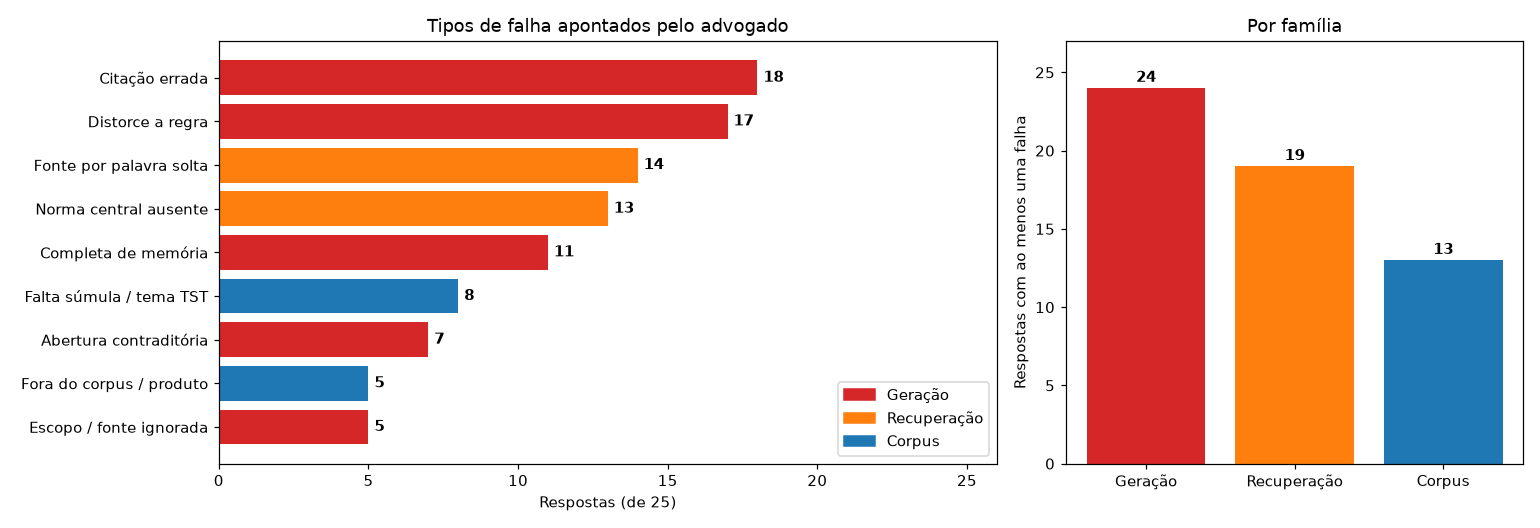

In [8]:
import importlib
import scripts.importar_revisao_juiz as imp
importlib.reload(imp)
TIPOS, FAMILIA = imp.TIPOS, imp.FAMILIA
CORES_FAMILIA = {'geração': '#d62728', 'recuperação': '#ff7f0e', 'corpus': '#1f77b4'}
ROTULOS = dict(memoria='Completa de memória', mecanismo='Distorce a regra', citacao='Citação errada',
               abertura='Abertura contraditória', escopo='Escopo / fonte ignorada', recall='Norma central ausente',
               ruido='Fonte por palavra solta', precedente='Falta súmula / tema TST', fronteira='Fora do corpus / produto')

d = df_diag.copy()
freq = pd.Series({t: int(d[t].sum()) for t in TIPOS}).sort_values()
familias = pd.DataFrame({f: d[[t for t in TIPOS if FAMILIA[t] == f]].any(axis=1) for f in CORES_FAMILIA})
print('Respostas com pelo menos uma falha de cada família (de 25):', {f: int(familias[f].sum()) for f in familias})
print(f"Respostas sem nenhuma marcação [Fonte N]: {int(d.sem_marcacao_fonte.sum())} de {len(d)} nesta amostra · "
      f"{int(df_fontes.sem_marcacao.sum())} de {len(df_fontes)} nas 111 respostas da geração")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.7, 1]})
axes[0].barh([ROTULOS[t] for t in freq.index], freq.values, color=[CORES_FAMILIA[FAMILIA[t]] for t in freq.index])
for i, v in enumerate(freq.values):
    axes[0].text(v + 0.2, i, str(v), va='center', fontweight='bold')
axes[0].set_xlim(0, len(d) + 1)
axes[0].set_xlabel('Respostas (de 25)')
axes[0].set_title('Tipos de falha apontados pelo advogado')
axes[0].legend(handles=[Patch(color=c, label=f.capitalize()) for f, c in CORES_FAMILIA.items()], loc='lower right')

cont = familias.sum()
axes[1].bar([f.capitalize() for f in cont.index], cont.values, color=list(CORES_FAMILIA.values()))
for i, v in enumerate(cont.values):
    axes[1].text(i, v + 0.4, str(int(v)), ha='center', fontweight='bold')
axes[1].set_ylim(0, len(d) + 2)
axes[1].set_ylabel('Respostas com ao menos uma falha')
axes[1].set_title('Por família')
plt.tight_layout()
plt.savefig(RELATORIOS / 'diagnostico_especialista.png', dpi=150)
plt.show()

### O que o juiz deixa passar

Cruzamos o diagnóstico com o juiz em duas perguntas. Quais falhas aparecem nas respostas que a regra fixa aprovou? E o juiz marca como "sem apoio" as afirmações que o advogado diz terem vindo de memória?

In [9]:
d = df_diag.merge(df_julg[['id', 'sem_apoio', 'fidelidade']], on='id', how='left')
por_regra = pd.DataFrame({regra: [int(d[d.veredito_regra == regra][t].sum()) for t in TIPOS]
                          for regra in ('aprovada', 'reprovada')}, index=TIPOS)
por_regra['família'] = [FAMILIA[t] for t in TIPOS]
display(por_regra.rename(columns={'aprovada': 'aprovadas pela regra (15)', 'reprovada': 'reprovadas pela regra (10)'}))

memoria = d[d.memoria]
print(f"Respostas em que o advogado aponta conteúdo de memória: {len(memoria)}")
print(f"  o juiz marcou ao menos uma afirmação sem apoio em {int((memoria.sem_apoio > 0).sum())} delas"
      f" · fidelidade média dada pelo juiz: {memoria.fidelidade.mean():.2f} de 2")
cit = d[d.citacao]
print(f"Respostas com citação errada (advogado): {len(cit)} · fidelidade média dada pelo juiz: {cit.fidelidade.mean():.2f} de 2")

Respostas em que o advogado aponta conteúdo de memória: 11
  o juiz marcou ao menos uma afirmação sem apoio em 3 delas · fidelidade média dada pelo juiz: 2.00 de 2
Respostas com citação errada (advogado): 18 · fidelidade média dada pelo juiz: 1.94 de 2


,aprovadas pela regra (15),reprovadas pela regra (10),família
memoria,7,4,geração
mecanismo,11,6,geração
citacao,10,8,geração
abertura,5,2,geração
escopo,2,3,geração
recall,8,5,recuperação
ruido,6,8,recuperação
precedente,4,4,corpus
fronteira,3,2,corpus


**Leitura do diagnóstico.**

1. **A geração é o gargalo principal, mesmo quando o contexto é bom.** Há um caso que mostra isso claramente: na pergunta do saque do FGTS (P19, q09_p1_JUS-007), o art. 20-A, § 2º, II, da Lei 8.036 estava nas fontes. Ele diz que, no saque-aniversário, a demissão sem justa causa não libera o saldo. Mesmo assim, a resposta omitiu essa regra e falou de "poupança digital", que não aparece em nenhuma fonte. As outras falhas de geração mais comuns:
   - citação errada;
   - mecanismo distorcido;
   - conteúdo de memória com leis que não estão nas fontes.
2. **Na recuperação, duas falhas se repetem:**
   - normas que só funcionam juntas chegam separadas (art. 20 sem o art. 18 da Lei 8.036; art. 3º sem os arts. 7º e 8º da Lei 7.998);
   - fontes chegam por uma palavra solta.

   O contrário também acontece: o art. 20 da Lei 8.036 chegou inteiro, com 16 mil caracteres, e a regra da rescisão ficou diluída no meio.
3. **No corpus, faltam os precedentes qualificados do TST.** A regra decisiva estava em súmulas como a 60, 338, 378, 276 e 6, e em temas como o 58 e o 125. Faltam também as matérias de fronteira e o FAQ do produto (perguntas sobre CPF, data de referência e consulta de processo).
4. **O juiz não enxerga boa parte dessas falhas.** Ele confere se a afirmação tem apoio nas fontes, mas não sabe se a norma citada existe, se o dispositivo é o certo nem se falta uma regra que não foi entregue. Os números mostram isso:
   - nas 11 respostas em que o advogado aponta conteúdo de memória, o juiz deu fidelidade média 2,00 de 2 e marcou afirmação sem apoio em só 3;
   - nas 18 com citação errada, a fidelidade média foi 1,94;
   - entre as 15 aprovadas pela regra, 10 têm citação errada e 11 têm a regra distorcida.

   Por isso o juiz aprova respostas com conteúdo de memória e com citação errada. Os critérios novos de que ele precisa são detectáveis por regra:
   - norma citada que não está nas fontes;
   - lei sustentada só por acórdão;
   - resposta normativa sem `[Fonte N]`.
5. **A marcação de fontes falta em 1 de cada 4 respostas.** São 28 das 111 respostas da geração sem nenhuma marcação `[Fonte N]`.

## 9. Por onde corrigir

As correções serão aplicadas e medidas no notebook 06, com comparação de antes e depois nas mesmas respostas e num grupo separado. A ordem vai do mais barato ao mais caro:

| Prioridade | Ação | O que resolve |
|---|---|---|
| 1 | Regra de citação no prompt: só citar `[Fonte N]` se o trecho contém a informação. Validador automático depois da geração: dispositivo × afirmação, norma fora das fontes, lei sustentada só por acórdão, no máximo 2 fontes por afirmação. Os mesmos critérios entram no juiz | Falhas de citação e de memória; juiz brando |
| 1 | Data atual no prompt; regra primeiro e exceção depois; preservar as condições de súmulas | Mecanismo distorcido e abertura invertida |
| 2 | Cota de entrega ajustada por teste (2+2 × 3+3 × 5+5); recuperação em bloco por lei e recorte de artigos longos; metadados de escopo (doméstico, rural, professor) e de vigência | Ruído, normas separadas, escopo |
| 3 | Nova base de precedentes (`notebooks/05_docs_precedentes`): súmulas, OJs e temas do TST, separada da jurisprudência | Regra decisiva que hoje falta no corpus |
| 3 | Bases curadas: rescisão, seguro-desemprego, tributação das verbas, jornada, dano moral, FAQ do produto | Perguntas de fronteira e de alta frequência |

**Teste do contexto ideal, antes de tudo.** Para 5 perguntas ruins (P19, P20, P23, P24 e P25), montamos à mão o contexto ideal e geramos a resposta de novo.
- Se o modelo acertar, o gargalo é a recuperação.
- Se errar mesmo com o contexto perfeito, o gargalo é a geração ou o prompt.

As respostas também viram os primeiros casos de regressão.

## 10. Conclusões

1. **Pelo juiz, o sistema parece bom.** Com o Gemma 3 27B, 67 das 111 respostas (60%) passam pela regra fixa, e 107 passam pelo veredito do próprio modelo. As notas médias são altas: fidelidade 1,80, correção 1,71 (só nas 28 respostas com referência), comportamento 1,77 e clareza 1,93. Só 7% das afirmações ficaram sem apoio, e 91% das decisões entregues foram julgadas pertinentes.
2. **Pelo especialista, não.** O advogado reprovou as 25 respostas da amostra, inclusive as 15 que a regra aprovou. A aprovação do juiz deve ser lida como um teto otimista, não como a qualidade real.
3. **O veredito do próprio modelo fica descartado.** A regra fixa continua como critério, mas precisa de critérios novos, detectáveis por regra: norma fora das fontes, lei sustentada só por acórdão e resposta sem `[Fonte N]`.
4. **O gargalo principal é a geração.** Em seguida vêm a recuperação (recall e ruído) e o corpus (precedentes do TST e matérias de fronteira). As correções estão priorizadas na seção 9 e serão medidas no notebook 06.
5. **Limites desta validação:**
   - um revisor só, com sinais de apoio de IA;
   - 25 respostas;
   - 10 vereditos inferidos das observações.

   Vale pedir ao revisor que confirme os vereditos em branco e, depois das correções, avaliar um lote novo.